# Conjunto de tiempos esperados: entrenamiento separado y planificación factible

**Pregunta:** ¿La política aprendida transfiere a depósitos no vistos y complementa el ordenamiento exacto por tiempos esperados?

**Nivel:** 4 · métodos propuestos. **Tiempo de lectura:** 45 minutos.


## Objetivos

Este experimento estudia una política de planificación desplegable, no un tutorial genérico de redes neuronales. La decisión es un orden de bloques y la salida es un plan factible. Las reglas posteriores de precedencia y capacidad son las mismas que para el comparador de referencia. La variable objetivo es el tiempo esperado de extracción, escalado por el horizonte. Es útil porque la heurística ExTS exacta existente ordena los bloques por tiempo esperado antes de construir un plan. La política aprendida aproxima ese orden con atributos disponibles para la tubería. La separación de entrenamiento y evaluación se realiza por semilla de depósito. Es más estricta que separar bloques individuales: los bloques de un mismo depósito sintético comparten geometría y estructura geológica, por lo que una separación por filas puede dejar parientes cercanos a ambos lados. El conjunto de prueba mide transferencia a depósitos generados nuevos. Cinco miembros comparten los datos de entrenamiento, pero usan semillas de inicialización fijas distintas. La predicción desplegada es su promedio. Este conjunto mide sensibilidad a la inicialización; no representa realizaciones geológicas independientes ni una distribución posterior calibrada.

## Preparación

Ejecute desde la raíz con `pip install oreblocks==0.6.5 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2`; versiones exactas: `oreblocks==0.6.5`, `numpy==2.5.1`, `scipy==1.18.1`, `matplotlib==3.11.2`. La lección lee los modelos y el informe versionados; nunca entrena ni instala paquetes en una celda. Un kernel nuevo reconstruye cada tabla y figura.

```bash
pip install oreblocks==0.6.5 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Importe las herramientas fijadas, cargue el método publicado y muestre las versiones del entorno.
import importlib.metadata as package_metadata
import json
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path('../../../').resolve()
sys.path.insert(0, str(ROOT / 'data-pipeline'))
from pipeline.model.learned import LearnedBundle  # noqa: E402
from pipeline.model.features import BLOCK_FEATURES  # noqa: E402
from pipeline.io.schema import Case, DepositSpec, Scenario  # noqa: E402
from pipeline.model.instances import build_instance  # noqa: E402
report = json.loads((ROOT / 'models/training-report.json').read_text(encoding='utf-8'))
bundle = LearnedBundle.load(ROOT / 'models')
metrics = bundle.report()['expectedTime']
for package in ('oreblocks','numpy','scipy','matplotlib'):
    print('paquete', package, '| versión', package_metadata.version(package))
print('atributos de bloque:', len(BLOCK_FEATURES), '| miembros del conjunto:', len(bundle.expected_time.members)+1)
print('semillas de prueba:', metrics['holdout_seeds'])


paquete oreblocks | versión 0.6.5
paquete numpy | versión 2.5.1
paquete scipy | versión 1.18.1
paquete matplotlib | versión 3.11.2
atributos de bloque: 11 | miembros del conjunto: 5
semillas de prueba: [211, 223, 227, 229, 233, 239]


## Datos

En inferencia, el modelo calcula once atributos ordenados de bloque, aplica normalización de entrenamiento, predice una fracción acotada y la convierte a períodos esperados. TopoSort construye entonces un plan bajo el grafo de precedencias y las capacidades. Ni la predicción ni el plan certifican una cota superior. El ordenamiento exacto por tiempos esperados es el comparador más cercano porque usa el mismo constructor con el objetivo conocido. MILP de ventana deslizante, formulaciones de destino y búsqueda local aportan contexto adicional, pero resuelven problemas restringidos distintos. Los resultados deben conservar sus etiquetas de método. La medida principal de utilidad es VPN descontado dividido por el VPN del plan ExTS exacto en el mismo caso. La correlación de rangos diagnostica el orden, pero puede ocultar inversiones económicamente relevantes. La factibilidad es obligatoria; el tiempo de cálculo y la cola de fallas ayudan a decidir cuándo sirve una heurística rápida.

Construya el depósito pequeño reproducible con la tubería del producto.


In [2]:
# Construya un caso didáctico acotado, con semilla y dos recursos declarados.
case = Case(
    id='bs1-vein-8x8x4', category='teaching',
    title_en='BS1 vein', title_es='Veta BS1',
    deposit=DepositSpec(
        kind='twin', archetype='vein', dims=(8,8,4), seed=223,
    ),
    scenario=Scenario(
        periods=6, discount_rate=0.10,
        capacity_fraction=(0.85,0.55),
        resource_names=('mining','processing'),
    ),
)
instance = build_instance(case)
print('contrato didáctico válido:', instance.report.ok, '| bloques:', instance.n_blocks)

contrato didáctico válido: True | bloques: 256


## Método

El benchmark usa depósitos sintéticos con geometría, semillas, capacidades, descuento y generación de escenarios declarados. El control sintético permite repetir el análisis, pero no demuestra transferencia a una mina con datos condicionados, restricciones operativas, historia de reconciliación o supuestos económicos cambiantes. La tabla de evidencia se lee del informe de entrenamiento versionado. Conserva semillas de prueba, razones por caso, mínimo, cuantiles y resúmenes por arquetipo. Una entrada licenciada ausente queda sin puntuación. No cuenta como éxito y el notebook no infiere archivos fuente ocultos. El umbral 0.90 es una convención diagnóstica explícita de este estudio, no un límite universal de aceptación. Su propósito es mostrar casos donde el plan pierde más de diez por ciento frente al comparador. Otras decisiones deben considerar costos, tolerancia al riesgo y un comparador exacto pertinente.

La llamada siguiente vuelve a abrir el modelo en vez de confiar en el primer objeto. Verifica el esquema del cargador de producción y rechaza escalas nulas o no finitas antes de usar el ordenamiento.

In [3]:
# Compruebe el cargador de producción y el orden contractual de sus atributos.
checked = LearnedBundle.load(ROOT / 'models')
assert tuple(checked.expected_time.feature_names) == tuple(BLOCK_FEATURES)
assert np.isfinite(checked.expected_time.sigma).all()
assert np.all(checked.expected_time.sigma > 1e-8)
print('nombres y orden del esquema verificados:', list(BLOCK_FEATURES))
print('todas las escalas de normalización son positivas:', bool(np.all(checked.expected_time.sigma > 0)))

nombres y orden del esquema verificados: ['value_norm', 'depth_frac', 'cone_size_norm', 'cone_value_norm', 'grade_norm', 'radial_frac', 'in_pit', 'rate', 'capacity_frac_0', 'capacity_frac_1', 'periods_norm']
todas las escalas de normalización son positivas: True


## Comparación

Una protección basada en arquetipos sintéticos puede alertar sobre una veta sintética conocida. Los depósitos reales quizá no tengan esa etiqueta. Por sí sola, la protección no vuelve seguro un caso real; siguen siendo necesarios una medición en el mismo caso o un método establecido conservador. La portabilidad del modelo se comprueba separada de su utilidad científica. Nombres y orden de atributos deben coincidir, las escalas ser finitas y positivas, y los valores ONNX y del navegador concordar con Python. Esa concordancia prueba paridad de implementación, no generalización ni valor económico.

Esta llamada al informe expone la evaluación de prueba persistida. La tabla separa ordenamiento, valor del plan y frecuencia de fallas porque cada uno describe una propiedad distinta.

In [4]:
# Consulte el informe del modelo y muestre las principales métricas de prueba.
live_report = checked.report()
score = live_report['expectedTime']
keys = [
    'holdout_spearman', 'holdout_mae_fraction',
    'holdout_npv_vs_exact_exts_median',
    'holdout_npv_vs_exact_exts_mean',
    'holdout_npv_vs_exact_exts_min',
    'holdout_beats_greedy_rate', 'failure_rate',
]
for key in keys:
    labels = {
    'holdout_spearman': 'Spearman de prueba',
    'holdout_mae_fraction': 'error absoluto medio de fracción',
    'holdout_npv_vs_exact_exts_median': 'mediana VPN aprendido/ExTS exacto',
    'holdout_npv_vs_exact_exts_mean': 'media VPN aprendido/ExTS exacto',
    'holdout_npv_vs_exact_exts_min': 'mínimo VPN aprendido/ExTS exacto',
    'holdout_beats_greedy_rate': 'fracción que supera al codicioso',
    'failure_rate': 'fracción bajo el umbral',
}
    print(f'{labels[key]}: {score[key]:.6f}')

Spearman de prueba: 0.813724
error absoluto medio de fracción: 0.045424
mediana VPN aprendido/ExTS exacto: 0.940548
media VPN aprendido/ExTS exacto: 0.940082
mínimo VPN aprendido/ExTS exacto: 0.710063
fracción que supera al codicioso: 0.921296
fracción bajo el umbral: 0.335648


## Evidencia

**Evidencia y límites.** Cambiar un atributo, etiqueta, partición, semilla de entrenamiento, peso del modelo, fuente de datos o resultado cambia la evidencia. Se debe recalcular toda la tubería, actualizar el informe y evitar que la interfaz presente agregados antiguos como si describieran el modelo nuevo. La evidencia negativa acompaña a la mediana favorable. El mínimo y la frecuencia de casos débiles determinan la conclusión. Un candidato rápido puede ser útil y aun requerir una alerta, un método alternativo o evaluación exacta para ciertos depósitos.

Ejecute la predicción por bloque y construcción de plan en el caso didáctico.

In [5]:
# Ejecute el predictor publicado y el constructor de planes factibles.
predicted_time = checked.predict_expected_times(instance, case.scenario)
learned_plan = checked.for_instance(instance)[0][1]
print('forma de las predicciones:', predicted_time.shape)
print('todas las predicciones son finitas:', bool(np.isfinite(predicted_time).all()))
print('VPN del plan construido:', round(learned_plan.npv, 2))

forma de las predicciones: (256,)
todas las predicciones son finitas: True
VPN del plan construido: 5632519.12


Estime la cota en el mismo caso y sepárela de resultados LP certificados.

In [6]:
# Ejecute el sustituto de la cota; su salida no es un certificado.
predicted_bound_ratio = checked.predict_bound_ratio(instance, case.scenario)
print('razón de cota predicha:', round(predicted_bound_ratio, 4))

razón de cota predicha: 0.4809


Evalúe la alerta dependiente de etiqueta en su arquetipo sintético previsto.

In [7]:
# Consulte la alerta para una clase sintética conocida y para una etiqueta desconocida.
vein_warning = checked.unreliable_here(instance.cpit, archetype=instance.archetype)
unknown_warning = checked.unreliable_here(instance.cpit, archetype=None)
print('la veta activa la alerta:', vein_warning is not None)
print('la etiqueta desconocida recibe clasificación:', unknown_warning is not None)

la veta activa la alerta: False
la etiqueta desconocida recibe clasificación: False


Agrupe las filas pareadas de depósito y escenario por arquetipo sintético para mostrar heterogeneidad. El resumen es descriptivo; no convierte al arquetipo en variable causal.

In [8]:
# Agrupe las razones por depósito sin excluir los casos débiles.
rows = report['expected_time_per_case']
archetypes = sorted({row['archetype'] for row in rows})
for name in archetypes:
    group = [row for row in rows if row['archetype'] == name]
    ratios = np.asarray([row['vs_true'] for row in group])
    wins = np.asarray([row['beats_greedy'] for row in group], dtype=float)
    print('arquetipo:', name, '| observaciones:', len(group))
    print('mediana/mínimo:', round(float(np.median(ratios)),3), round(float(np.min(ratios)),3))
    print('victorias frente al codicioso:', round(float(wins.mean()),3))

arquetipo: core_halo | observaciones: 108
mediana/mínimo: 0.935 0.736
victorias frente al codicioso: 1.0
arquetipo: layered | observaciones: 108
mediana/mínimo: 0.943 0.854
victorias frente al codicioso: 0.685
arquetipo: porphyry | observaciones: 108
mediana/mínimo: 0.997 0.88
victorias frente al codicioso: 1.0
arquetipo: vein | observaciones: 108
mediana/mínimo: 0.867 0.71
victorias frente al codicioso: 1.0


Inspeccione la configuración del conjunto entrenado mediante el objeto del método. Las semillas distintas y las épocas fijadas hacen reproducible el experimento; no son muestras de prueba independientes adicionales.

In [9]:
# Consulte el método del modelo e informe la configuración de entrenamiento congelada.
print('método de predicción:', checked.predict_expected_times.__name__)
print('semillas de los miembros:', checked.expected_time.metrics['ensemble_seeds'])
print('épocas por miembro:', checked.expected_time.metrics['epochs'])
probe = checked.expected_time.forward(np.zeros((1, len(BLOCK_FEATURES))))
print('la prueba normalizada es finita:', bool(np.isfinite(probe).all()))

método de predicción: predict_expected_times
semillas de los miembros: [17, 29, 41, 53, 67]
épocas por miembro: 10
la prueba normalizada es finita: True


La llamada a la protección demuestra el límite de etiquetas desconocidas. No tener clasificación no es un resultado positivo de seguridad; el producto debe mantener visible esta diferencia.

In [10]:
# Consulte la alerta del producto sin arquetipo conocido e inspeccione su calidad medida.
unknown_label_warning = checked.unreliable_here(None, archetype=None)
print('sin etiqueta se abstiene de clasificar:', unknown_label_warning is None)
print('regla de falla:', score.get('failure_rule'))
precision = score.get('failure_rule_precision')
recall = score.get('failure_rule_recall')
print('precisión / exhaustividad de la alerta:', precision, recall)

sin etiqueta se abstiene de clasificar: True
regla de falla: archetype == vein
precisión / exhaustividad de la alerta: 0.7407407407407407 0.5517241379310345


Grafique todas las razones de prueba por arquetipo, incluidos los extremos, para mostrar la dispersión empírica detrás de la mediana.

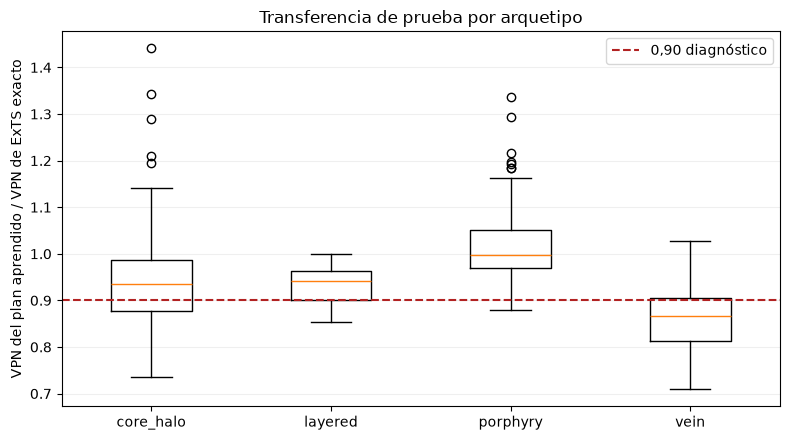

In [11]:
# Grafique todas las razones aprendidas/ExTS exacto de prueba, incluida la cola de fallas.
archetypes = sorted({row['archetype'] for row in rows})
fig, ax = plt.subplots(figsize=(8,4.5))
series = [[row['vs_true'] for row in rows if row['archetype']==name] for name in archetypes]
ax.boxplot(series, tick_labels=archetypes, showfliers=True)
ax.axhline(.90,color='firebrick',linestyle='--',label='0,90 diagnóstico')
ax.set(ylabel='VPN del plan aprendido / VPN de ExTS exacto',title='Transferencia de prueba por arquetipo')
ax.legend()
ax.grid(axis='y',alpha=.2)
fig.tight_layout()
plt.show()

La dispersión importa para decidir: la línea 0.90 es una convención diagnóstica, no un teorema ni un criterio universal. Cada punto corresponde a un caso de depósito y escenario de prueba; las razones débiles permanecen visibles y no se ocultan con la mediana. Un desempeño similar entre familias generadas tampoco demostraría transferencia a geología minera condicionada. La agrupación por arquetipo solo diagnostica este estudio sintético y su etiqueta quizá no exista para un depósito real.

Compare la tasa de victoria codiciosa por separado. No equivale a la razón con ExTS exacto y ayuda a entender por qué una base débil no debe definir el éxito del producto.

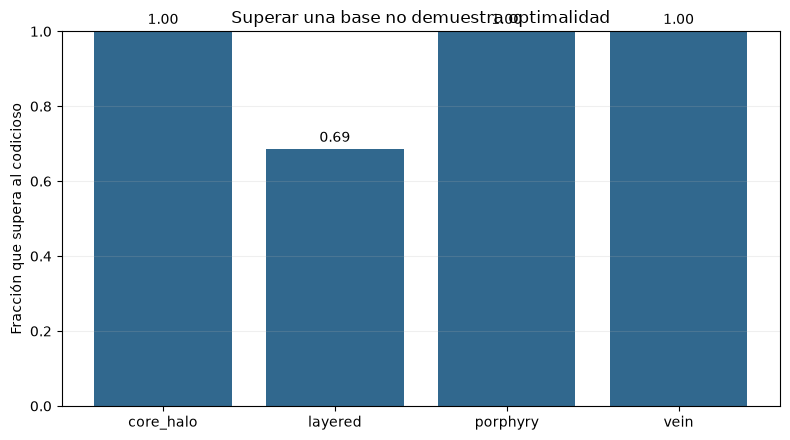

In [12]:
# Grafique la fracción de casos que supera la base constructiva codiciosa.
wins = []
for name in archetypes:
    group = [row for row in rows if row['archetype']==name]
    wins.append(sum(bool(row['beats_greedy']) for row in group)/len(group))
fig, ax = plt.subplots(figsize=(8,4.5))
ax.bar(archetypes,wins,color='#31688e')
ax.set(ylim=(0,1),ylabel='Fracción que supera al codicioso',title='Superar una base no demuestra optimalidad')
for i,value in enumerate(wins):
    ax.text(i,value+.02,f'{value:.2f}',ha='center')
ax.grid(axis='y',alpha=.2)
fig.tight_layout()
plt.show()

Superar un plan codicioso constructivo es una afirmación más débil que igualar ExTS exacto. Lea el gráfico junto a la distribución de razones VPN y la comparación pareada. La política sigue siendo una heurística de plan factible; no reemplaza cotas LP certificadas ni optimización exacta en casos tratables. Si no existe un comparador exacto del mismo caso, el producto debe marcar el resultado sin puntuación en vez de inferir éxito a partir de métricas de transferencia.

## Resultados

**Respuesta:** El estudio ejecutado informa mediana VPN aprendido/ExTS exacto de 0.9405, mínimo de 0.7101 y 33.56% de casos de prueba bajo 0.90. Supera al método codicioso en 92.13% de los casos. La transferencia es útil pero irregular, no una garantía general.

## Resumen

Lea el resultado en tres escalas: depósito individual, resumen por arquetipo y prueba agregada. La primera detecta transferencias catastróficas; la segunda revela heterogeneidad estructurada; la tercera comunica una tendencia central compacta. Ninguna reemplaza las demás. No use la mediana agregada como promesa de liberación ni como etiqueta para depósitos reales no vistos. El límite del experimento es un plan CPIT factible bajo el escenario declarado de dos recursos. No optimiza selección de destino, acceso a fases, mezcla, asignación de equipos ni recourse operacional. Esas restricciones pueden cambiar prioridades de bloques y deben modelarse antes de trasladar esta política a decisiones de producción.

## Referencias

Código y modelos CAOS PhaseFlow: https://github.com/fsantibanezleal/CAOS_PhaseFlow; Kingma y Ba, Adam: https://arxiv.org/abs/1412.6980; Newman, formulaciones de secuenciación de rajos: https://doi.org/10.1287/inte.2013.0731; Blom, Pearce y Cote, Large Neighbourhood Search: https://arxiv.org/abs/2403.18213.